# 30. Финальный эксперимент: какая сцена помещается

[Программа курса](../../README_ru.md)

Есть скульптура, канал для передачи 2200 байт и просмотрщик, который рисует кадр 80 × 60. Большой пакет не пролезет. Самый маленький пролезет, но может потерять цвет. Вместо одного «лучшего» способа получится короткий список измерений, правило выбора и файл, с которым опыт можно повторить.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "compression_math.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import compression_math as codec
import compression_demos as demos
from reconstruction import scores, benchmark
from splat_render import render_scene, orbit_camera
lang = "ru"

## Две фотографии с разными ролями

Сначала зафиксируем всё, что может незаметно изменить ответ. Одна исходная модель из 117 пятен, белый фон, те же параметры камеры, разрешение 80 × 60 и одна версия рендерера. Все четыре пакета рисуют фотографию `view-00.jpg`. Этот кадр уже участвовал в обучении исходной скульптуры. Здесь он играет роль калибровочного примера для выбора способа упаковки. Кадр `view-04.jpg` был отложен при обучении. Его результат появится только после выбора. Если снова и снова подстраивать пороги по отложенному снимку, для следующей независимой проверки понадобится новый ракурс.

У ошибки на всех $80\cdot60\cdot3=14400$ числах простая механика. Вычитаем эталонный канал из канала модели, берём квадрат, складываем и делим на 14400. Если красный равен 0.7 вместо 0.6, в сумму попадёт $(0.7-0.6)^2=0.01$. На нормированном RGB максимальное значение канала равно 1. Тогда PSNR в децибелах равна $10\log_{10}(1/\mathrm{MSE})$. Для средней ошибки 0.01 отношение равно 100; $10^2=100$, значит логарифм равен 2 и итог равен 20 дБ. У идеального совпадения MSE равна нулю и PSNR бесконечна.

In [2]:
settings_path = course / 'data' / 'codec-study' / 'settings.json'
cfg = json.loads(settings_path.read_text(encoding='utf8'))
report = codec.benchmark_photo(cfg)
for r in report['candidates']:
    print(f"{r['name']:14} {r['bytes']:5} B   {r['validationPsnr']:.3f} dB   "
          f"decode {r['decodeMs']:.3f} ms   frame {r['renderMs']:.3f} ms")
print(report['selected'], report['test'])

f32-rgb         6560 B   20.244 dB   decode 0.350 ms   frame 76.152 ms
u8-rgb          1694 B   20.271 dB   decode 0.138 ms   frame 57.356 ms
u8-half          882 B   19.272 dB   decode 0.084 ms   frame 26.897 ms
u8-gray-half     764 B   19.191 dB   decode 0.115 ms   frame 26.539 ms
u8-rgb {'view': 'view-04.jpg', 'mse': 0.00983929764663813, 'psnr': 20.07035901474754}


## Как из четырёх строк остаётся одна

| Пакет | Что хранится | Байт | PSNR на view-00 |
|---|---|---:|---:|
| f32-rgb | 117 пятен в float32 | 6560 | 20.24 дБ |
| u8-rgb | Те же 117 в uint8 | 1694 | 20.27 дБ |
| u8-half | 59 цветных пятен | 882 | 19.27 дБ |
| u8-gray-half | 59 серых пятен | 764 | 19.19 дБ |

Здесь PSNR сравнивает каждый вариант **с фотографией**. Поэтому маленькое округление иногда чуть улучшает отдельный пиксель несовершенной исходной модели. Разница в 0.03 дБ на одной камере не доказывает, что округление улучшает сцену вообще.

Правило выбора фиксируется заранее. Размер не больше 2200 байт и качество на калибровочном ракурсе не ниже 16 дБ. Первый пакет отсекается: $6560>2200$. Три других проходят оба порога. При приоритете качества их лучший результат — 20.27 дБ у `u8-rgb`. На передачу уходит в $6560/1694\approx3.87$ раза меньше байт, чем в исходном float32. Теперь открывается отложенный кадр. Там MSE примерно 0.009839, так что $10\log_{10}(1/0.009839)\approx20.07$ дБ. Если вместо качества приоритетом станет размер, пройдёт серый пакет в 764 байта.

In [3]:
display(demos.codec_lab(30, lang))

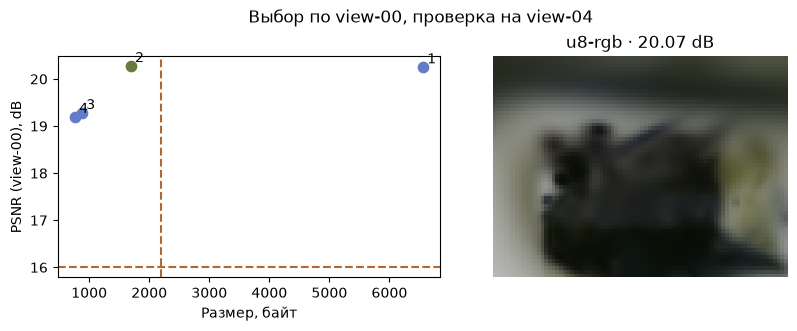

In [4]:
demos.study_figure(report, lang)
plt.show()

## Время, память и устройство

Пакет декодируется один раз при открытии. Каждый новый кадр приходится рисовать заново. Если чтение заняло 1 мс, а один кадр 25 мс, то за 40 кадров получится $1+40\cdot25=1001$ мс без передачи по сети. Для плавных 30 кадров в секунду на кадр есть $1000/30\approx33.3$ мс, включая остальную работу приложения. При приоритете времени выбирается допустимый пакет с наименьшей измеренной медианой рендера. Цена передачи и время чтения в этот рейтинг не сложены.

Один прогрев убирает часть стартовых затрат. Три замера 22, 24 и 61 мс дали бы медиану 24 мс — среднее по порядку значение. Замеры на CPU в NumPy и в JavaScript относятся к разным реализациям. В браузере короткие вызовы измеряются сериями. У итогового RGB float64 один кадр занимает $80\cdot60\cdot3\cdot8=115200$ байт. Это только выходной массив. Ни полный пик памяти процесса, ни требования к видеопамяти из него не следуют. В [сохранённом отчёте](../../data/codec-study/reference.json) рядом с замерами записаны ОС, архитектура и версии библиотек. Для другого устройства особенно важен повторный замер скорости.

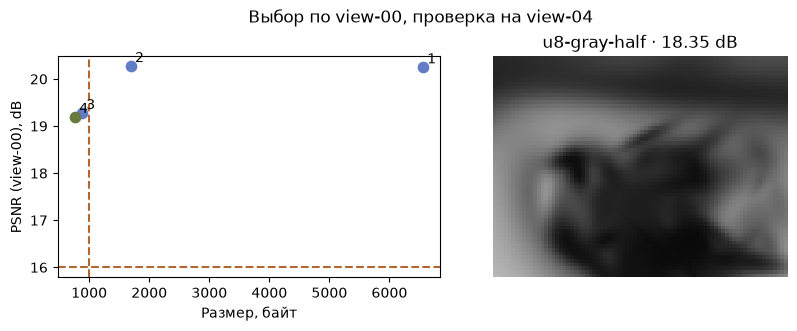

80 × 60 × 3 × 8 = 115200 bytes


In [5]:
demos.study_figure(report, lang, max_bytes=1000, min_psnr=16, priority='size')
plt.show()
print('80 × 60 × 3 × 8 =', report['candidates'][0]['bufferBytes'], 'bytes')

## А если подавать движение?

У скульптуры достаточно один раз записать центры. У ленты из урока 26 центры меняются. Чтобы сравнение вариантов было честным, оставим один и тот же канонический пакет и прибавим к нему движение. Каноническая часть в этом учёте хранится целиком, включая стартовые центры. Частота кадров и длительность клипа в этой таблице заранее известны. Заголовки транспорта не учитываются.

Дадим движению отдельно 500 байт. Для пяти пятен полная запись 17 положений требует 1036 и не пройдёт. Опоры шагом 8 требуют 196 байт, с поправками — 406. Теперь интересно качество между опорами. Ячейка берёт моменты 0.19, 0.37 и 0.71 с, которых нет в записанной сетке. Два ракурса видят одно движение. Сначала складываем MSE шести одинаковых по размеру кадров и делим на шесть, затем переводим среднюю ошибку в дБ. Это оценка потерь упаковки относительно исходного движения урока 26. Снимки скульптуры здесь уже ни при чём.

In [6]:
from deformation import scene_at
model, xyz = codec.motion_data()
base = len(codec.pack_static(model['canonical'], 'f32'))
for mode in ['dense', 'keys', 'residual']:
    packet = codec.pack_motion(xyz, mode, stride=8, quantum=.002)
    track = codec.unpack_motion(packet)
    errors = []
    for t in [.19, .37, .71]:
        decoded = codec.pose_with_centers(model['canonical'], codec.sample_track(track, t))
        for angle in [-25, 32]:
            camera = orbit_camera(angle, 55)
            image = render_scene(decoded, camera, 65, 49)
            target = render_scene(scene_at(model, t), camera, 65, 49)
            errors.append(scores(image, target)['mse'])
    print(mode, 'motion B:', len(packet), 'total B:', base+len(packet),
          'PSNR dB:', round(-10*np.log10(np.mean(errors)), 2),
          'decode ms:', round(benchmark(lambda: codec.unpack_motion(packet)), 4))

dense motion B: 1036 total B: 1324 PSNR dB: 69.49 decode ms: 0.0048
keys motion B: 196 total B: 484 PSNR dB: 29.52 decode ms: 0.0738
residual motion B: 406 total B: 694 PSNR dB: 69.36 decode ms: 0.0831


## Файл для следующего прогона

[Настройки опыта](../../data/codec-study/settings.json) сохраняют пределы, приоритет, разрешение и число повторов. В веб-опыте тот же JSON можно сохранить после изменения полей и открыть заново. Из корня репозитория [скрипт сравнения](../../scripts/benchmark_codecs.py) принимает этот файл и записывает новый отчёт:

```sh
python scripts/benchmark_codecs.py --settings data/codec-study/settings.json --output codec-report.json
```

Число байтов и картинки определяются исходными данными и правилами округления. Время — живой замер. Поэтому два компьютера с одинаковыми настройками могут выбрать разные пакеты при приоритете скорости.

**Опыт.** При лимите 900 байт и пороге 19.25 дБ какой вариант сохранится? Что будет, если поднять порог до 19.5 дБ?

<details>
<summary>Разбор</summary>

В 900 байт помещаются два пакета. Цветной набрал примерно 19.27 дБ и проходит порог 19.25. Серый с 19.19 дБ отпадает. При 19.5 дБ не проходит ни один. Здесь честный ответ — подходящего варианта среди этих четырёх нет. Можно увеличить доступный размер или исследовать промежуточную долю пятен в уроке 28.

</details>